# 18 ARIMA und SARIMAX auf dem Tagesrücklauf

- Taugen ARIMA oder SARIMAX für den Tagesrücklauf, und lässt sich damit die Wirkung einer Begehung ohne Jahreszeiteneffekt messen (Problem aus NB 03 und 16)?
- Außentemperatur (DWD Kitzingen, NB 07) als exogene Größe; Regression mit AR-Fehlern (SARIMAX ohne MA-Teil) in `src/zeitreihenmodell.py`, da statsmodels fehlt
- Ablauf: Modellvergleich ohne Begehung, Prognose der Zeit nach der Begehung aus dem Vorher-Modell, Placebo und Kontrollgruppe. Eine Abweichung ist ein Hinweis, kein Nachweis

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import weather
from src import zeitreihenmodell as zm

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 4)

## Daten und Tagesreihe

- Stundenreihen aus Notebook 00 über `src/nb00_daten.py`
- Tagesmittel des Rücklaufs aus Stunden über 0,5 kW, mindestens 12 Stunden je Tag; Tage ab 15 °C Außentemperatur und Lücken bleiben leer

In [2]:
#Stundenreihen aus Notebook 00 (data/processed/real_meters)
serien = nb00.lade_serien()
ladefehler = nb00.nicht_aufbereitet()
hist_von = min(d.index[0] for d in serien.values() if len(d)).normalize()
hist_bis = max(d.index[-1] for d in serien.values() if len(d)).normalize()
t_out = weather.load_outdoor_temperature(hist_von, hist_bis + pd.Timedelta(days=1),
                                         allow_download=False)

tage = {z: zm.tagesreihe(d, t_out) for z, d in serien.items() if len(d)}
heiztage = pd.Series({z: int(t["y"].notna().sum()) for z, t in tage.items()})
print(f"{len(serien)} Zählerreihen geladen, {len(ladefehler)} nicht ladbar")
print(f"Historie {hist_von.date()} .. {hist_bis.date()} ({(hist_bis - hist_von).days} Tage)")
print(f"Außentemperatur: {len(t_out)} Stunden, "
      f"{int(t_out['interpolated'].sum())} interpoliert")
print()
print("gültige Heiztage je Zähler (Tagesmittel Rücklauf mit Last, Außentemperatur unter 15 °C):")
display(heiztage.describe().round(0))
print(f"Zähler mit weniger als 120 gültigen Heiztagen: {(heiztage < 120).sum()}")
print(f"Zähler mit weniger als 40: {(heiztage < 40).sum()}")

100 Zählerreihen geladen, 1 nicht ladbar
Historie 2021-05-31 .. 2026-07-20 (1876 Tage)
Außentemperatur: 45044 Stunden, 7 interpoliert

gültige Heiztage je Zähler (Tagesmittel Rücklauf mit Last, Außentemperatur unter 15 °C):


count    100.0
mean     325.0
std      149.0
min        0.0
25%      253.0
50%      333.0
75%      393.0
max      647.0

Zähler mit weniger als 120 gültigen Heiztagen: 10
Zähler mit weniger als 40: 6


## Die verglichenen Modelle

- Spezialfälle von `u = y - X*beta`, `phi(L) * Phi(L^7) * (1-L)^d * u = Fehler`: ohne exogene Spalte und mit d = 1 ARIMA, mit Außentemperatur und Wochenterm (Periode 7) SARIMAX
- `kennlinie`: reine Regression Rücklauf gegen Außentemperatur, zeigt den Beitrag der AR-Terme

In [3]:
modelle = zm.standard_modelle()
beschr = pd.DataFrame([{
    "modell": s.name,
    "AR p": s.p,
    "saisonal P (7 Tage)": s.P,
    "Differenz d": s.d,
    "exogen": ", ".join(s.exog) or "-",
    "Konstante": s.konstante and s.d == 0,
} for s in modelle])
beschr.loc[len(beschr)] = ["naiv_7", 0, 0, 0, "-", "Mittel der letzten 7 Tage"]
display(beschr)

,modell,AR p,saisonal P (7 Tage),Differenz d,exogen,Konstante
0,arima_110,1,0,1,-,False
1,arma_200,2,0,0,-,True
2,kennlinie,0,0,0,t_out,True
3,arx_100,1,0,0,t_out,True
4,sarimax_100_100,1,1,0,t_out,True
5,sarimax_lag,1,1,0,"t_out, t_out_l1",True
6,naiv_7,0,0,0,-,Mittel der letzten 7 Tage


## Teil 1: Prognosefehler ohne Begehung

- Je Zähler Fenster mit 56 Tagen Anpassung und 14 Tagen Prognose bei bekannter Außentemperatur, ohne Begehung im Fenster

In [4]:
begehungen_je_meter = lb.begehung_dates_by_meter(available=set(serien))

teile = []
for z, t in tage.items():
    if t["y"].notna().sum() < 120:
        continue
    r = zm.rollender_vergleich(t, modelle, train_tage=56, horizont=14, schritt=14,
                               sperrdaten=begehungen_je_meter.get(z, []))
    if len(r):
        r["meter"] = z
        teile.append(r)
kurz = pd.concat(teile, ignore_index=True)

#nur Fenster, in denen alle Modelle eine Prognose haben
voll = kurz.groupby(["meter", "ursprung"])["modell"].transform("nunique") == kurz["modell"].nunique()
kurz = kurz[voll]
w = kurz.pivot_table(index=["meter", "ursprung"], columns="modell", values="mae")
print(f"{w.index.get_level_values('meter').nunique()} Zähler, {len(w)} Prognosefenster à 14 Tage")

tab = kurz.groupby("modell")[["mae", "rmse", "bias"]].mean().round(2)
tab["mae_median"] = kurz.groupby("modell")["mae"].median().round(2)
tab["besser_als_naiv"] = [round(float((w[m] < w["naiv_7"]).mean()), 2) for m in tab.index]
tab = tab.sort_values("mae")
display(tab)

87 Zähler, 1538 Prognosefenster à 14 Tage


,mae,rmse,bias,mae_median,besser_als_naiv
modell,,,,,
arx_100,2.12,2.55,0.21,1.63,0.67
sarimax_100_100,2.21,2.66,0.12,1.65,0.64
sarimax_lag,2.24,2.70,0.10,1.65,0.62
kennlinie,2.28,2.71,0.20,1.70,0.63
naiv_7,2.69,3.17,0.03,2.01,0.00
arma_200,2.71,3.20,-0.02,2.03,0.50
arima_110,2.82,3.33,-0.11,2.13,0.42


In [5]:
#Paarvergleich je Zähler (Mittel über die Fenster), damit nicht jedes Fenster
#einzeln zählt, obwohl die Fenster eines Zählers nicht unabhängig sind
wm = w.groupby("meter").mean()
paare = [("arx_100", "naiv_7"), ("arx_100", "arima_110"), ("arx_100", "kennlinie"),
         ("sarimax_100_100", "arx_100"), ("sarimax_lag", "sarimax_100_100"),
         ("arima_110", "naiv_7"), ("arma_200", "naiv_7")]
zeilen = []
for a, b in paare:
    diff = wm[a] - wm[b]
    zeilen.append({
        "A": a, "B": b,
        "Median MAE A - B (°C)": round(float(diff.median()), 3),
        "Zähler mit A besser": f"{int((diff < 0).sum())} von {len(diff)}",
        "Wilcoxon p": float(f"{stats.wilcoxon(wm[a], wm[b]).pvalue:.2g}"),
    })
display(pd.DataFrame(zeilen))
print()
print("bestes Modell je Zähler (kleinster mittlerer MAE):")
display(wm.idxmin(axis=1).value_counts())

,A,B,Median MAE A - B (°C),Zähler mit A besser,Wilcoxon p
0,arx_100,naiv_7,-0.317,69 von 87,5.600000e-10
1,arx_100,arima_110,-0.497,77 von 87,2.100000e-14
2,arx_100,kennlinie,-0.024,60 von 87,1.700000e-04
3,sarimax_100_100,arx_100,0.022,27 von 87,2.900000e-03
4,sarimax_lag,sarimax_100_100,0.018,35 von 87,2.000000e-01
5,arima_110,naiv_7,0.192,24 von 87,4.200000e-05
6,arma_200,naiv_7,0.029,41 von 87,3.700000e-01



bestes Modell je Zähler (kleinster mittlerer MAE):


arx_100            32
sarimax_lag        15
kennlinie          13
naiv_7             11
sarimax_100_100    10
arima_110           3
arma_200            3

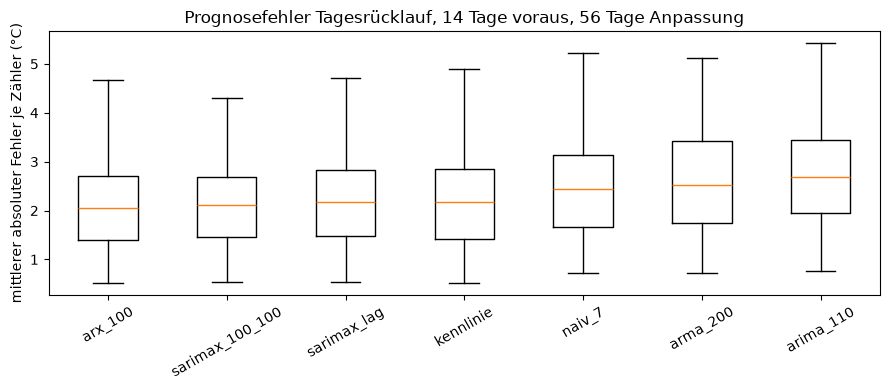

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
reihenfolge = tab.index.tolist()
ax.boxplot([wm[m].dropna() for m in reihenfolge], showfliers=False)
ax.set_xticklabels(reihenfolge)
ax.set_ylabel("mittlerer absoluter Fehler je Zähler (°C)")
ax.set_title("Prognosefehler Tagesrücklauf, 14 Tage voraus, 56 Tage Anpassung")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

- `arx_100` (Außentemperatur plus AR(1)) am besten, im Median je Zähler 0,32 °C besser als das 7-Tage-Mittel und 0,50 °C besser als ARIMA(1,1,0)
- Reines ARIMA ist schlechter als naiv, ohne Wetter schreibt es nur den letzten Stand fort
- Wochenterm bringt nichts, der AR-Term gegenüber der reinen Kennlinie nur 0,02 °C: der Gewinn kommt aus der Außentemperatur

## Teil 2: Prognosefenster für die Begehungen

- Anpassung auf bis zu 365 Tagen vor dem Termin (nur Heiztage), Prognose der folgenden 90 Tage; Vorjahresvergleich über die Außentemperatur statt über den Kalender
- Dieselbe Fensterlänge ohne Begehung liefert das Prognoserauschen

In [7]:
exogene = [s for s in modelle if s.exog]
teile = []
for z, t in tage.items():
    if t["y"].notna().sum() < 120:
        continue
    r = zm.rollender_vergleich(t, exogene, train_tage=365, horizont=90, schritt=30,
                               min_train_gueltig=40, min_test_gueltig=10,
                               sperrdaten=begehungen_je_meter.get(z, []))
    if len(r):
        r["meter"] = z
        teile.append(r)
lang = pd.concat(teile, ignore_index=True)
voll = lang.groupby(["meter", "ursprung"])["modell"].transform("nunique") == lang["modell"].nunique()
lang = lang[voll]

#robuste Streuung der Abweichung ohne Begehung, Grundlage für den z-Wert
def robust_sd(s):
    return 1.4826 * np.median(np.abs(s - np.median(s)))


sd_lang = lang.groupby("modell")["bias"].agg(robust_sd)
tl = lang.groupby("modell")[["mae", "rmse", "bias"]].mean().round(2)
tl["mae_median"] = lang.groupby("modell")["mae"].median().round(2)
tl["sd_bias_robust"] = sd_lang.round(2)
print(f"{lang['meter'].nunique()} Zähler, {lang.groupby(['meter','ursprung']).ngroups} Fenster "
      f"(365 Tage Anpassung, 90 Tage Prognose, ohne Begehung im Fenster)")
display(tl.sort_values("mae"))

71 Zähler, 799 Fenster (365 Tage Anpassung, 90 Tage Prognose, ohne Begehung im Fenster)


,mae,rmse,bias,mae_median,sd_bias_robust
modell,,,,,
arx_100,3.41,4.03,-0.40,2.34,1.76
kennlinie,3.46,4.06,-0.51,2.35,1.77
sarimax_lag,3.56,4.18,-0.46,2.38,1.86
sarimax_100_100,3.59,4.21,-0.43,2.46,1.92
naiv_7,3.88,4.59,-0.45,2.85,2.44


- Abweichung = Messung minus Prognose, gemittelt über die Heiztage danach; negativ = Rücklauf niedriger als bei gleichem Wetter erwartet
- `z` = Abweichung geteilt durch die robuste Streuung ohne Begehung (MAD mal 1,4826)

In [8]:
MODELL = "arx_100"
spec = {s.name: s for s in modelle}
sd = float(sd_lang[MODELL])

beg = lb.begehungen_mit_zaehler(available=set(serien)).dropna(subset=["meter", "datum"])
beg["meter"] = beg["meter"].astype(int)
zeilen = []
for _, r in beg.iterrows():
    t = tage.get(r["meter"])
    if t is None:
        continue
    zeile = {"meter": r["meter"], "datum": r["datum"].normalize(), "kategorie": r["kategorie"],
             "zaehlerwechsel": bool(r.get("meter_gewechselt", False))}
    for name in ("kennlinie", "arx_100", "sarimax_100_100"):
        wk = zm.wirkung_begehung(t, r["datum"], spec[name])
        zeile[name] = np.nan if wk is None else wk["abw"]
        if name == MODELL and wk is not None:
            zeile["n_post"] = wk["n_post"]
            zeile["rt_vor"] = wk["rt_vor"]
            zeile["rt_nach"] = wk["rt_nach"]
    zeilen.append(zeile)
ergebnis = pd.DataFrame(zeilen)
ergebnis["z"] = ergebnis[MODELL] / sd
ok = ergebnis.dropna(subset=[MODELL]).copy()

print(f"{len(ergebnis)} Begehungen mit Zähler und Datum, {len(ok)} auswertbar "
      f"({len(ergebnis) - len(ok)} ohne genug Heiztage davor oder danach)")
print(f"Begehungsdatum der auswertbaren: {ok['datum'].min().date()} .. {ok['datum'].max().date()}")
print()
display(ok.sort_values("z")[["meter", "datum", "kategorie", "zaehlerwechsel", "kennlinie",
                              "arx_100", "sarimax_100_100", "n_post", "z"]].round(2)
        .reset_index(drop=True))

53 Begehungen mit Zähler und Datum, 40 auswertbar (13 ohne genug Heiztage davor oder danach)
Begehungsdatum der auswertbaren: 2024-08-26 .. 2025-09-16



,meter,datum,kategorie,zaehlerwechsel,kennlinie,arx_100,sarimax_100_100,n_post,z
0,68956351,2024-09-09,viele,False,-32.59,-32.52,-32.46,46.0,-18.53
1,68956372,2024-10-14,viele,False,-14.91,-15.65,NaN,90.0,-8.91
2,68956355,2024-09-16,viele,False,-10.95,-10.88,-10.50,77.0,-6.20
3,69527345,2024-09-17,viele,False,-11.51,-9.59,-6.10,75.0,-5.46
4,80912190,2024-09-12,mittlere,False,-9.94,-8.85,-7.36,73.0,-5.04
5,68956345,2024-09-18,mittlere,False,-8.83,-8.85,-8.99,77.0,-5.04
6,80912197,2024-09-20,geringe,False,-7.51,-7.27,-7.27,73.0,-4.14
7,80912193,2024-11-05,mittlere,False,-6.09,-4.44,-5.22,90.0,-2.53
8,68956359,2024-09-26,mittlere,False,-4.28,-4.30,-4.58,39.0,-2.45
9,68956373,2025-03-12,mittlere,False,-4.33,-4.19,-4.41,24.0,-2.39


In [9]:
print("Kategorie der Begehung gegen Abweichung (arx_100, °C; negativ = Rücklauf niedriger als erwartet):")
display(ok.groupby("kategorie")[MODELL].agg(["count", "median", "mean"]).round(2))
print()
#Modellvergleich auf den Begehungen: stimmen die drei exogenen Modelle überein?
exo = ok[["kennlinie", "arx_100", "sarimax_100_100"]].dropna()
print("Rangkorrelation der Abweichungen zwischen den Modellen (n = %d):" % len(exo))
display(exo.corr(method="spearman").round(3))
print()
#Abgleich mit dem bisherigen Vorher/Nachher aus Notebook 03
alt = pd.read_csv("../data/processed/begehungs_wirkung.csv", parse_dates=["datum"])
vgl = ok.merge(alt[["meter", "datum", "d_rt", "did"]], on=["meter", "datum"], how="inner")
print(f"Abgleich mit Notebook 03 (Rücklaufänderung nachher minus vorher): {len(vgl)} gemeinsame Begehungen")
for spalte in ("d_rt", "did"):
    v = vgl.dropna(subset=[spalte])
    rho, p = stats.spearmanr(v[MODELL], v[spalte])
    print(f"  Spearman Modellabweichung gegen {spalte}: rho = {rho:.2f}, p = {p:.3g}, n = {len(v)}")

Kategorie der Begehung gegen Abweichung (arx_100, °C; negativ = Rücklauf niedriger als erwartet):


,count,median,mean
kategorie,,,
geringe,3,7.33,2.82
keine,2,-1.35,-1.35
mittlere,25,-1.15,-0.89
viele,10,-0.60,-6.47



Rangkorrelation der Abweichungen zwischen den Modellen (n = 37):


,kennlinie,arx_100,sarimax_100_100
kennlinie,1.000,0.993,0.978
arx_100,0.993,1.000,0.988
sarimax_100_100,0.978,0.988,1.000



Abgleich mit Notebook 03 (Rücklaufänderung nachher minus vorher): 38 gemeinsame Begehungen
  Spearman Modellabweichung gegen d_rt: rho = 0.55, p = 0.000349, n = 38
  Spearman Modellabweichung gegen did: rho = 0.53, p = 0.000592, n = 38


- 40 von 53 Begehungen auswertbar, die exogenen Modelle sind sich einig (Rangkorrelation mindestens 0,97)
- Zusammenhang mit der Rücklaufänderung aus NB 03 (Spearman 0,55, n = 38), aber kein unabhängiger Beleg

## Teil 3: Placebo und Kontrollgruppe

- Placebo: wie oft liegt ein Fenster ohne Begehung außerhalb von z = ±2? Kontrolle: Stationen ohne Begehung mit Pseudodatum aus den echten Terminen

In [10]:
def anteile(z, schwelle=2.0):
    z = np.asarray(z, dtype=float)
    z = z[np.isfinite(z)]
    return int((np.abs(z) > schwelle).sum()), len(z)


p_alle = lang[lang["modell"] == MODELL].copy()
p_alle["z"] = p_alle["bias"] / sd
p_herbst = p_alle[p_alle["ursprung"].dt.month.isin([8, 9, 10, 11])]

n_b, m_b = anteile(ok["z"])
n_a, m_a = anteile(p_alle["z"])
n_h, m_h = anteile(p_herbst["z"])
print("Anteil Fenster mit |z| > 2:")
print(f"  Begehungen:                   {n_b} von {m_b} ({n_b / m_b:.0%})")
print(f"  Fenster ohne Begehung, alle:  {n_a} von {m_a} ({n_a / m_a:.0%})")
print(f"  Fenster ohne Begehung, Aug-Nov: {n_h} von {m_h} ({n_h / m_h:.0%})")
for name, (n, m) in {"alle": (n_a, m_a), "Aug-Nov": (n_h, m_h)}.items():
    p = stats.binomtest(n_b, m_b, n / m, alternative="greater").pvalue
    print(f"  Binomialtest Begehung gegen Placebo {name}: p = {p:.3g}")

neg = (ok["z"] < -2).sum()
pos = (ok["z"] > 2).sum()
print()
print(f"Begehungen mit z < -2 (Rücklauf deutlich niedriger): {neg}, mit z > 2 (höher): {pos}")
print(f"Placebo Aug-Nov: z < -2 in {(p_herbst['z'] < -2).mean():.1%}, z > 2 in {(p_herbst['z'] > 2).mean():.1%}")

Anteil Fenster mit |z| > 2:
  Begehungen:                   15 von 40 (38%)
  Fenster ohne Begehung, alle:  141 von 799 (18%)
  Fenster ohne Begehung, Aug-Nov: 55 von 309 (18%)
  Binomialtest Begehung gegen Placebo alle: p = 0.00232
  Binomialtest Begehung gegen Placebo Aug-Nov: p = 0.00253

Begehungen mit z < -2 (Rücklauf deutlich niedriger): 10, mit z > 2 (höher): 5
Placebo Aug-Nov: z < -2 in 13.3%, z > 2 in 4.5%


In [11]:
#Kontrollgruppe: Stationen ohne Begehung bekommen ein Pseudodatum aus den echten
#Begehungsterminen, damit beide Gruppen im selben Kalenderfenster liegen
rng = np.random.default_rng(42)
echte_termine = ok["datum"].tolist()
mit_begehung = set(beg["meter"])
kontrolle = []
for z, t in tage.items():
    if z in mit_begehung or t["y"].notna().sum() < 120:
        continue
    for ziehung in range(3):
        datum = echte_termine[rng.integers(len(echte_termine))]
        wk = zm.wirkung_begehung(t, datum, spec[MODELL])
        if wk is not None:
            kontrolle.append({"meter": z, "datum": datum, "ziehung": ziehung, "abw": wk["abw"]})
kontrolle = pd.DataFrame(kontrolle)
kontrolle["z"] = kontrolle["abw"] / sd
print(f"Kontrolle: {kontrolle['meter'].nunique()} Stationen ohne Begehung, "
      f"{len(kontrolle)} Pseudotermine (je Station bis zu 3 Ziehungen)")

n_k, m_k = anteile(kontrolle["z"])
print(f"|z| > 2: Begehung {n_b} von {m_b} ({n_b / m_b:.0%}), Kontrolle {n_k} von {m_k} ({n_k / m_k:.0%})")
print(f"Median Abweichung: Begehung {ok[MODELL].median():+.2f} °C, Kontrolle {kontrolle['abw'].median():+.2f} °C")
auff = kontrolle.loc[kontrolle["z"].abs() > 2, "meter"].nunique()
print(f"Kontrollstationen mit mindestens einer Ziehung |z| > 2: {auff} von {kontrolle['meter'].nunique()}")
u = stats.mannwhitneyu(ok[MODELL], kontrolle["abw"])
print(f"Mann-Whitney Begehung gegen Kontrolle: p = {u.pvalue:.3g}")
fe = stats.fisher_exact([[n_b, m_b - n_b], [n_k, m_k - n_k]])
print(f"Fisher für Anteil |z| > 2: p = {fe[1]:.3g}")
print()
print("Kontrolle mit |z| > 2, je Station (Pseudodatum):")
display(kontrolle[kontrolle["z"].abs() > 2].round(2).sort_values("z").reset_index(drop=True))

Kontrolle: 39 Stationen ohne Begehung, 108 Pseudotermine (je Station bis zu 3 Ziehungen)
|z| > 2: Begehung 15 von 40 (38%), Kontrolle 20 von 108 (19%)
Median Abweichung: Begehung -0.85 °C, Kontrolle -0.04 °C
Kontrollstationen mit mindestens einer Ziehung |z| > 2: 9 von 39
Mann-Whitney Begehung gegen Kontrolle: p = 0.207
Fisher für Anteil |z| > 2: p = 0.0279

Kontrolle mit |z| > 2, je Station (Pseudodatum):


,meter,datum,ziehung,abw,z
0,72167777,2024-09-19,0,-27.06,-15.42
1,69513891,2024-08-26,1,-21.27,-12.12
2,69513891,2024-09-23,0,-20.56,-11.71
3,80912158,2024-09-23,1,-10.89,-6.20
4,80912158,2024-09-20,2,-10.89,-6.20
5,69513891,2024-11-19,2,-9.69,-5.52
6,72167782,2024-11-06,1,-7.24,-4.13
7,72167782,2024-11-08,0,-7.06,-4.02
8,72167777,2024-10-14,2,-6.81,-3.88
9,72135480,2024-09-19,2,-6.70,-3.82


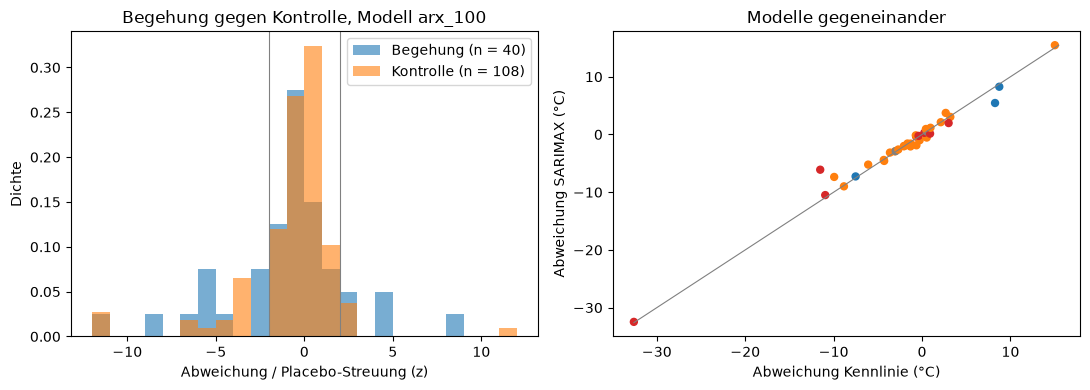

In [12]:
fig, achsen = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(-12, 12, 25)
achsen[0].hist(np.clip(ok["z"], -12, 12), bins=bins, alpha=0.6, density=True, label=f"Begehung (n = {len(ok)})")
achsen[0].hist(np.clip(kontrolle["z"], -12, 12), bins=bins, alpha=0.6, density=True, label=f"Kontrolle (n = {len(kontrolle)})")
achsen[0].axvline(-2, color="grey", lw=0.8)
achsen[0].axvline(2, color="grey", lw=0.8)
achsen[0].set_xlabel("Abweichung / Placebo-Streuung (z)")
achsen[0].set_ylabel("Dichte")
achsen[0].legend()
achsen[0].set_title("Begehung gegen Kontrolle, Modell arx_100")

o = ok.sort_values("z")
farben = o["kategorie"].map({"keine": "grey", "geringe": "tab:blue", "mittlere": "tab:orange", "viele": "tab:red"}).fillna("black")
achsen[1].scatter(o["kennlinie"], o["sarimax_100_100"], c=farben, s=25)
grenze = [min(o["kennlinie"].min(), o["sarimax_100_100"].min()), max(o["kennlinie"].max(), o["sarimax_100_100"].max())]
achsen[1].plot(grenze, grenze, color="grey", lw=0.8)
achsen[1].set_xlabel("Abweichung Kennlinie (°C)")
achsen[1].set_ylabel("Abweichung SARIMAX (°C)")
achsen[1].set_title("Modelle gegeneinander")
plt.tight_layout()

Koeffizienten: {'konstante': 67.77, 't_out': 0.44} phi: [0.7]
Rücklauf vor der Begehung (Heiztage, Mittel): 70.5 °C
Rücklauf danach: 37.7 °C, Prognose des Vorher-Modells: 71.9 °C


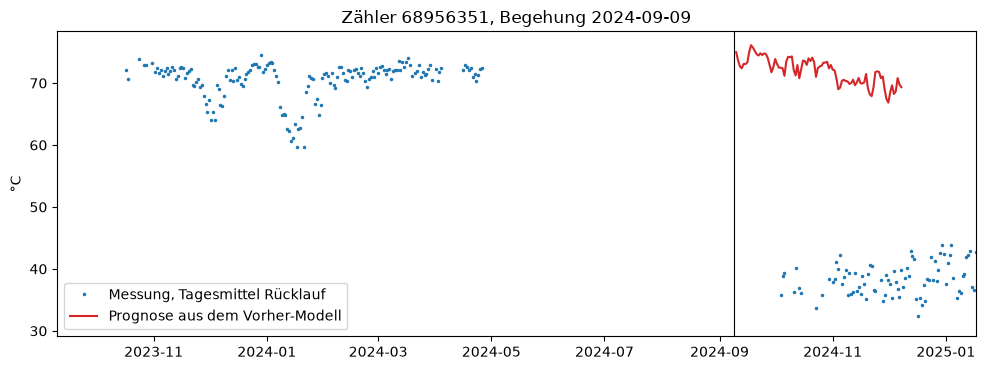

In [13]:
#Einzelfall mit bekanntem Befund: Ventil über drei Jahre offen, Reparatur 09.09.2024
#steht nicht in der Begehungstabelle (Zähler 68956351)
fall = tage[68956351]
beginn = pd.Timestamp("2024-09-09")
train = fall.loc[beginn - pd.Timedelta(days=365):beginn - pd.Timedelta(days=1)]
post = fall.loc[beginn + pd.Timedelta(days=1):beginn + pd.Timedelta(days=90)]
anp = zm.fit(train, spec[MODELL])
pred = pd.Series(zm.prognose(anp, train, post), index=post.index)
print("Koeffizienten:", {k: round(float(v), 2) for k, v in zip(anp.spalten, anp.beta)}, "phi:", anp.phi.round(2))
print(f"Rücklauf vor der Begehung (Heiztage, Mittel): {train['y'].mean():.1f} °C")
print(f"Rücklauf danach: {post['y'].mean():.1f} °C, Prognose des Vorher-Modells: {pred.mean():.1f} °C")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(fall.index, fall["y"], ".", ms=3, color="tab:blue", label="Messung, Tagesmittel Rücklauf")
ax.plot(pred.index, pred, color="tab:red", label="Prognose aus dem Vorher-Modell")
ax.axvline(beginn, color="black", lw=0.8)
ax.set_xlim(beginn - pd.Timedelta(days=365), beginn + pd.Timedelta(days=130))
ax.set_ylabel("°C")
ax.legend()
ax.set_title("Zähler 68956351, Begehung 2024-09-09")
plt.tight_layout()

In [14]:
aus = Path("../data/processed")
ok.to_csv(aus / "arima_begehungen.csv", index=False)
kurz.groupby("modell")[["mae", "rmse", "bias"]].mean().to_csv(aus / "arima_modellvergleich.csv")
print("geschrieben: data/processed/arima_begehungen.csv, arima_modellvergleich.csv (gitignored)")

geschrieben: data/processed/arima_begehungen.csv, arima_modellvergleich.csv (gitignored)


## Zusammenfassung & Bewertung

- Ergebnis: bestes Modell Außentemperatur mit AR(1)-Fehlern, mittlerer Fehler 2,12 °C gegen 2,69 naiv (87 Zähler, 1538 Fenster). 15 von 40 Begehungen (38 %) liegen außerhalb von z = ±2, gegen 18 % der Placebo-Fenster (p = 0,002) und 19 % der Kontrollstationen (Fisher p = 0,028), 10 davon mit niedrigerem Rücklauf
- Belastbar: die Außentemperatur lohnt sich als Erklärungsgröße; nach Begehungen gibt es häufiger einen deutlichen Sprung als bei Kontrollstationen. Stärkste Abweichung bei 68956351 (70,5 °C vorher, 37,7 °C nachher, Erwartung 71,9 °C), ohne Labelwissen gefunden
- Schwach: kein Beleg für Zeitreihenstruktur bei Tagesmitteln; der typische Fall ändert sich wenig (Median −0,85 gegen −0,04 °C, p = 0,21); Ziehungen je Kontrollstation nicht unabhängig
- Offen: große Sprünge im Herbst 2024 ohne Begehung (72167777 rund −27 °C, 69513891 −21 °C, 80956410 +20 °C), nur über Rückfrage zu klären; 13 Begehungen nicht auswertbar; praktisch nur ein Anpassungswinter; Außentemperatur aus Kitzingen statt Wiesentheid; ob die Abweichung als Merkmal in die Fallsammlung geht